# Лабораторная работа 3. ETL и ELT-пайплайны

*Выполнил студент группы МОАм-251 Аношин Антон.*

Беру выгрузку ДТП из первой работы и собираю ежедневную сводку по регионам. Это адаптация сценария ежедневной аналитики: расчёт до 06:00 МСК, отчёт к 07:00. Использую ELT: сначала сохраняю данные, потом строю витрины через dbt.

## Подготовка

Зависимости - в [requirements.txt](requirements.txt). Код пайплайна здесь, SQL - в [dbt/](dbt/), CI - в [workflow](../.github/workflows/lab03.yml). База и отчёты создаются в `_work/lab_03/`. Беру 2025 год и три региона, исходные данные не меняю.

In [1]:
import hashlib, inspect, json, os, subprocess, sys, time, uuid
from datetime import datetime, timedelta, timezone
from pathlib import Path
import pandas as pd
import duckdb
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'requirements.txt').is_file() and (p / 'lab_03').is_dir())
sys.path.insert(0, str(ROOT))
DATA = Path(os.environ.get('DTP_DATA_DIR', str(ROOT / 'data')))
BASE = Path(os.environ.get('LAB3_WORK_DIR', str(ROOT / '_work/lab_03'))).resolve()
WORK = BASE / 'sessions' / os.environ.get('LAB3_SESSION', uuid.uuid4().hex[:10])
WORK.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('PREFECT_HOME', str(BASE / 'prefect'))
Path(os.environ['PREFECT_HOME']).mkdir(parents=True, exist_ok=True)
os.environ['PYTHONUTF8'] = '1'
if os.name == 'nt':
    site = Path(sys.prefix) / 'Lib/site-packages'
    alias = Path(os.environ['LOCALAPPDATA']) / 'Temp/opencode' / ('lab03-site-' + hashlib.sha256(str(site).encode()).hexdigest()[:8])
    alias.parent.mkdir(parents=True, exist_ok=True)
    if not alias.exists():
        command = "New-Item -ItemType Junction -Path '" + str(alias).replace("'", "''") + "' -Target '" + str(site).replace("'", "''") + "' | Out-Null"
        subprocess.run(['powershell', '-NoProfile', '-Command', command], check=True, capture_output=True)
    sys.path.insert(0, str(alias))
    os.environ['PYTHONPATH'] = str(alias) + os.pathsep + os.environ.get('PYTHONPATH', '')
os.environ.setdefault('PREFECT_SERVER_ANALYTICS_ENABLED', 'false')
os.environ.setdefault('PREFECT_LOGGING_LEVEL', 'CRITICAL')
os.environ['GX_ANALYTICS_ENABLED'] = 'False'
import great_expectations as gx
from great_expectations.data_context.types.base import ProgressBarsConfig
from prefect import flow, task
from prefect.tasks import exponential_backoff
from prefect.cache_policies import NO_CACHE
from prefect.context import get_run_context
from prefect.client.schemas.schedules import CronSchedule
from prefect.utilities.asyncutils import run_coro_as_sync

FIELDS = ['accident_id', 'reg_code', 'dt', 'dead_n', 'injured_n', 'vehicles_n']
NUMBERS = ['reg_code', 'dead_n', 'injured_n', 'vehicles_n']
REGIONS = [1132, 1140, 1145]
DB = WORK / 'warehouse.duckdb'
PROJECT = WORK / 'dbt'
FAULTS = {}

### Вспомогательные функции

In [2]:
def sql(query, params=None):
    with duckdb.connect(str(DB)) as db:
        return db.execute(query, params or []).fetchdf()

def notify(message):
    sql("INSERT INTO alerts VALUES (?, current_timestamp)", [message])

def init_storage():
    sql("CREATE SCHEMA IF NOT EXISTS raw")
    sql("CREATE SCHEMA IF NOT EXISTS analytics")
    sql("""CREATE TABLE IF NOT EXISTS raw.accidents (
        idempotency_key VARCHAR PRIMARY KEY, accident_id VARCHAR UNIQUE, reg_code BIGINT, dt TIMESTAMP,
        dead_n BIGINT, injured_n BIGINT, vehicles_n BIGINT, source_version BIGINT, payload_hash VARCHAR)""")
    sql("""CREATE TABLE IF NOT EXISTS dlq (
        error_key VARCHAR PRIMARY KEY, reason VARCHAR, payload VARCHAR, created_at TIMESTAMPTZ)""")
    sql("CREATE TABLE IF NOT EXISTS alerts (message VARCHAR, created_at TIMESTAMPTZ)")
    sql("CREATE TABLE IF NOT EXISTS audit (run_id VARCHAR, stage VARCHAR, status VARCHAR, seconds DOUBLE, row_count BIGINT, detail VARCHAR)")
    sql("CREATE TABLE IF NOT EXISTS versions (version VARCHAR PRIMARY KEY, snapshot VARCHAR, published_at TIMESTAMPTZ)")
    sql("CREATE TABLE IF NOT EXISTS active_version (version VARCHAR)")

def quarantine(records, reasons):
    rows = []
    for record, reason in zip(records.to_dict('records'), reasons):
        payload = json.dumps(record, ensure_ascii=False, sort_keys=True, default=str)
        rows.append([hashlib.sha256((reason + payload).encode()).hexdigest(), reason, payload])
    if rows:
        with duckdb.connect(str(DB)) as db:
            db.executemany("INSERT INTO dlq VALUES (?, ?, ?, current_timestamp) ON CONFLICT DO NOTHING", rows)
        notify(f'DLQ: отклонено {len(rows)} записей')

def signature():
    frame = sql('SELECT * FROM analytics.daily ORDER BY day, reg_code')
    body = frame.astype(str).to_json(orient='records')
    return {'rows': len(frame), 'accidents': int(frame.accidents.sum()),
            'dead': int(frame.dead.sum()), 'injured': int(frame.injured.sum()),
            'checksum': hashlib.sha256(body.encode()).hexdigest()}

def restore(version):
    path = sql('SELECT snapshot FROM versions WHERE version=?', [version]).iloc[0, 0]
    with duckdb.connect(str(DB)) as db:
        db.execute('BEGIN')
        db.execute('CREATE OR REPLACE TABLE restored_daily AS SELECT * FROM read_parquet(?)', [path])
        db.execute('CREATE OR REPLACE VIEW analytics.daily AS SELECT * FROM restored_daily')
        db.execute('DELETE FROM active_version')
        db.execute('INSERT INTO active_version VALUES (?)', [version])
        db.execute('COMMIT')
    return signature()

def source_batch():
    if os.environ.get('LAB3_CI') == '1':
        return pd.DataFrame([
            [f'ci-{r}-{i}', r, pd.Timestamp('2025-01-01') + pd.Timedelta(days=i), 0, 1, 2]
            for r in REGIONS for i in range(5)], columns=FIELDS)
    source = DATA / 'clean/accidents/year=2025/part.parquet'
    if not source.exists():
        raise FileNotFoundError(f'{source}: задайте DTP_DATA_DIR или LAB3_CI=1 для встроенных тестовых данных')
    frame = pq.ParquetFile(source).read(columns=FIELDS).to_pandas()
    return frame[frame.reg_code.isin(REGIONS)].reset_index(drop=True)

def extract(batch=None):
    frame = source_batch() if batch is None else batch.copy()
    body = frame.to_json(orient='records', lines=True, date_format='iso')
    folder = WORK / 'incoming'
    folder.mkdir(exist_ok=True)
    path = folder / (hashlib.sha256(body.encode()).hexdigest() + '.jsonl')
    if not path.exists():
        temporary = path.with_suffix('.tmp')
        temporary.write_text(body, encoding='utf-8')
        temporary.replace(path)
    frame.attrs['batch_path'] = str(path)
    return frame

def contract(frame):
    if 'dead_n' not in frame and 'killed_n' in frame:
        frame = frame.rename(columns={'killed_n': 'dead_n'})
        notify('Schema drift: применён совместимый алиас killed_n -> dead_n')
    missing = set(FIELDS) - set(frame)
    if missing:
        reason = 'schema_missing:' + ','.join(sorted(missing))
        quarantine(pd.DataFrame([{'batch_path': frame.attrs.get('batch_path'), 'rows': len(frame)}]), [reason])
        raise ValueError(reason)
    if set(frame) - set(FIELDS):
        notify('Schema drift: дополнительные поля сохранены в incoming, в контракт не включены')
    return frame[FIELDS].copy()

In [3]:
def quality(frame, label='input', mart=False):
    context = gx.get_context(mode='ephemeral')
    context.variables.progress_bars = ProgressBarsConfig(globally=False)
    definition = (context.data_sources.add_pandas('dtp').add_dataframe_asset('batch')
                  .add_batch_definition_whole_dataframe('all'))
    suite = gx.ExpectationSuite(name='dtp_quality')
    columns = ['day', 'reg_code', 'accidents', 'dead', 'injured', 'victims'] if mart else FIELDS
    frame = frame.copy()
    key = 'grain' if mart else 'accident_id'
    if mart:
        frame['grain'] = frame.day.astype(str) + '|' + frame.reg_code.astype(str)
        frame['expected_victims'] = frame.dead + frame.injured
    checks = [gx.expectations.ExpectColumnValuesToNotBeNull(column=c) for c in columns]
    checks += [gx.expectations.ExpectColumnValuesToBeUnique(column=key),
               gx.expectations.ExpectColumnValuesToBeInSet(column='reg_code', value_set=list(region_names))]
    checks += [gx.expectations.ExpectColumnValuesToBeBetween(column=c, min_value=0)
               for c in (['accidents', 'dead', 'injured', 'victims'] if mart else NUMBERS[1:])]
    if mart:
        checks.append(gx.expectations.ExpectColumnPairValuesToBeEqual(column_A='victims', column_B='expected_victims'))
    for check in checks:
        suite.add_expectation(check)
    result = definition.get_batch(batch_parameters={'dataframe': frame}).validate(suite)
    report = pd.DataFrame([{'проверка': r.expectation_config.type,
                           'поле': r.expectation_config.kwargs.get('column'),
                           'успех': bool(r.success), 'нарушений': r.result.get('unexpected_count', 0)}
                          for r in result.results])
    report.to_html(WORK / f'quality_{label}.html', index=False)
    return report

def validate(frame):
    original = frame.drop_duplicates('accident_id', keep='last').copy()
    frame = original.copy()
    frame['dt'] = pd.to_datetime(frame.dt, errors='coerce')
    for column in NUMBERS:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
    reasons = pd.Series('', index=frame.index)
    checks = {'empty_id': frame.accident_id.notna() & frame.accident_id.astype(str).str.strip().ne(''),
              'bad_date': frame.dt.notna(), 'unknown_region': frame.reg_code.isin(region_names)}
    checks.update({f'bad_{c}': frame[c].notna() & frame[c].ge(0) & frame[c].mod(1).eq(0) for c in NUMBERS[1:]})
    for reason, valid in checks.items():
        reasons.loc[~valid] += reason + ';'
    quality(frame, 'before')
    bad = reasons.ne('')
    quarantine(original.loc[bad], reasons.loc[bad])
    good = frame.loc[~bad].copy()
    if good.empty:
        raise ValueError('Нет валидных записей')
    good[NUMBERS] = good[NUMBERS].astype('int64')
    report = quality(good, 'after')
    if not report['успех'].all():
        raise ValueError('Great Expectations отклонил подготовленные данные')
    good.attrs.update(rejected=int(bad.sum()), quality_score=float(report['успех'].mean()))
    return good

def load(frame, revision):
    batch = frame[FIELDS].copy()
    batch.insert(0, 'idempotency_key', batch.accident_id.map(lambda x: hashlib.sha256(str(x).encode()).hexdigest()))
    batch['source_version'] = revision
    batch['payload_hash'] = frame[FIELDS].astype(str).apply(
        lambda row: hashlib.sha256('|'.join(row).encode()).hexdigest(), axis=1)
    with duckdb.connect(str(DB)) as db:
        db.register('incoming', batch)
        db.execute("""INSERT INTO raw.accidents SELECT * FROM incoming
            ON CONFLICT (idempotency_key) DO UPDATE SET
              reg_code=excluded.reg_code, dt=excluded.dt, dead_n=excluded.dead_n,
              injured_n=excluded.injured_n, vehicles_n=excluded.vehicles_n,
              source_version=excluded.source_version, payload_hash=excluded.payload_hash
            WHERE excluded.source_version > raw.accidents.source_version""")
    return {'rows': len(batch)}

In [4]:
def prepare_project():
    import shutil
    shutil.copytree(ROOT / 'lab_03/dbt', PROJECT, dirs_exist_ok=True)
    (PROJECT / 'seeds').mkdir(exist_ok=True)
    pd.DataFrame(region_names.items(), columns=['reg_code', 'reg_name']).to_csv(
        PROJECT / 'seeds/dim_regions.csv', index=False)

def dbt(command, schema, broken=False):
    env = os.environ | {'LAB3_DB': DB.as_posix(), 'LAB3_SCHEMA': schema, 'DBT_SEND_ANONYMOUS_USAGE_STATS': 'false'}
    process = subprocess.run([sys.executable, '-m', 'dbt.cli.main', *command,
                              '--project-dir', str(PROJECT), '--profiles-dir', str(PROJECT),
                              '--vars', json.dumps({'break_model': broken})],
                             env=env, capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=120)
    log = process.stdout + process.stderr
    (WORK / 'dbt_last.log').write_text(log, encoding='utf-8')
    if process.returncode:
        raise ValueError(log[-2500:])
    return log

def transform(broken=False):
    content = sql('SELECT idempotency_key, payload_hash FROM raw.accidents ORDER BY idempotency_key')
    files = [p for folder in ['models', 'macros', 'tests', 'seeds'] for p in sorted((PROJECT / folder).rglob('*')) if p.is_file()]
    model_code = ''.join(p.read_text(encoding='utf-8') for p in files)
    digest = hashlib.sha256((content.to_json(orient='records') + model_code + str(broken)).encode()).hexdigest()[:16]
    schema = 'candidate_' + digest
    dbt(['build'], schema, broken)
    results = json.loads((PROJECT / 'target/run_results.json').read_text(encoding='utf-8'))
    return {'schema': schema, 'rows': len(content), 'tests': results['results']}

def postcheck(candidate):
    report = quality(sql(f"SELECT * FROM {candidate['schema']}.fact_daily"), 'mart', mart=True)
    if not report['успех'].all():
        raise ValueError('Great Expectations отклонил витрину')
    return candidate

def publish(candidate, deadline, fail_smoke=False):
    if datetime.now(timezone.utc) > deadline:
        notify('SLA: превышен бюджет обработки, предыдущая витрина сохранена')
        raise ValueError('SLA exceeded')
    schema = candidate['schema']
    frame = sql(f'SELECT * FROM {schema}.fact_daily ORDER BY day, reg_code')
    snapshot = WORK / 'snapshots' / (schema + '.parquet')
    snapshot.parent.mkdir(exist_ok=True)
    if not snapshot.exists():
        temporary = snapshot.with_suffix('.tmp')
        frame.to_parquet(temporary, index=False)
        temporary.replace(snapshot)
    with duckdb.connect(str(DB)) as db:
        db.execute('BEGIN')
        try:
            db.execute(f'CREATE OR REPLACE VIEW analytics.daily AS SELECT * FROM {schema}.fact_daily')
            rows = db.execute('SELECT sum(accidents) FROM analytics.daily').fetchone()[0]
            if fail_smoke or rows != candidate['rows'] or frame.empty:
                raise ValueError('Canary/smoke test failed')
            db.execute('INSERT INTO versions VALUES (?, ?, current_timestamp) ON CONFLICT DO NOTHING', [schema, str(snapshot)])
            db.execute('DELETE FROM active_version')
            db.execute('INSERT INTO active_version VALUES (?)', [schema])
            db.execute('COMMIT')
        except Exception:
            db.execute('ROLLBACK')
            raise
    return {'version': schema, 'rows': int(rows)}

In [5]:
def result_of(state):
    result = state.result(raise_on_failure=False)
    return run_coro_as_sync(result) if inspect.isawaitable(result) else result

def transient(task, task_run, state):
    return isinstance(result_of(state), OSError)

@task(retries=2, retry_delay_seconds=exponential_backoff(backoff_factor=0.1),
      retry_condition_fn=transient, task_run_name='{name}', cache_policy=NO_CACHE, persist_result=False)
def step(name, run_id, **kwargs):
    start = time.perf_counter()
    try:
        if FAULTS.get(name, 0):
            FAULTS[name] -= 1
            raise OSError('Учебный временный сбой: ' + name)
        result = {'extract': extract, 'contract': contract, 'validate': validate,
                  'load': load, 'transform': transform, 'postcheck': postcheck, 'publish': publish}[name](**kwargs)
        rows = len(result) if isinstance(result, pd.DataFrame) else result.get('rows', 0)
        status, detail = 'completed', ''
        return result
    except Exception as exc:
        rows, status, detail = 0, 'retry' if isinstance(exc, OSError) else 'failed', str(exc)[-500:]
        raise
    finally:
        sql('INSERT INTO audit VALUES (?, ?, ?, ?, ?, ?)',
            [run_id, name, status, time.perf_counter() - start, rows, detail])

@flow(name='region-load', persist_result=False, validate_parameters=False)
def region_flow(frame, revision, run_id):
    return step('load', run_id, frame=frame, revision=revision)

@flow(name='DTP ELT', persist_result=False, validate_parameters=False)
def pipeline(batch=None, revision=1, broken=False, fail_smoke=False, budget=3600):
    run_id = str(get_run_context().flow_run.id)
    start = time.perf_counter()
    deadline = datetime.now(timezone.utc) + timedelta(seconds=budget)
    frame = step('extract', run_id, batch=batch)
    frame = step('contract', run_id, frame=frame)
    good = step('validate', run_id, frame=frame)
    for _, region in good.groupby('reg_code'):
        region_flow(region, revision, run_id)
    candidate = step('transform', run_id, broken=broken)
    candidate = step('postcheck', run_id, candidate=candidate)
    release = step('publish', run_id, candidate=candidate, deadline=deadline, fail_smoke=fail_smoke)
    return release | {'run_id': run_id, 'seconds': time.perf_counter() - start,
                      'rejected': good.attrs['rejected'], 'quality_score': good.attrs['quality_score']}

def run(batch=None, fault=None, failures=1, **kwargs):
    FAULTS.clear()
    if fault:
        FAULTS[fault] = failures
    state = pipeline(batch, return_state=True, **kwargs)
    result = result_of(state)
    return {'ok': state.is_completed(), 'result': result if state.is_completed() else None,
            'error': '' if state.is_completed() else str(result)[-250:]}

def check_idempotency(batch):
    first = run(batch)
    assert first['ok'], first['error']
    before = signature()
    versions = len(sql('SELECT * FROM versions'))
    second = run(pd.concat([batch, batch.head(5)], ignore_index=True))
    assert second['ok'], second['error']
    assert signature() == before and len(sql('SELECT * FROM versions')) == versions
    assert sql('SELECT count(*) - count(DISTINCT idempotency_key) AS n FROM raw.accidents').iloc[0, 0] == 0
    return first['result'], before

def check_errors(batch):
    checks = []
    for name in ['extract', 'contract', 'validate', 'load', 'transform', 'postcheck', 'publish']:
        result = run(batch, fault=name)
        assert result['ok'], result['error']
        checks.append({'проверка': 'retry: ' + name, 'успех': result['ok']})
    before = signature()
    exhausted = run(batch, fault='extract', failures=5)
    assert not exhausted['ok'] and FAULTS['extract'] == 2 and signature() == before
    checks.append({'проверка': 'retry limit: 3 attempts', 'успех': True})
    for label, frame, options in [
        ('missing column', batch.drop(columns='dt'), {}),
        ('dbt failed', batch, {'broken': True}),
        ('canary failed', batch, {'fail_smoke': True}),
        ('SLA exceeded', batch, {'budget': 0}),
    ]:
        result = run(frame, **options)
        assert not result['ok'] and signature() == before
        checks.append({'проверка': label, 'успех': True})
    return pd.DataFrame(checks)

def show_monitoring():
    audit = sql('SELECT * FROM audit')
    display(audit.groupby(['stage', 'status']).agg(запусков=('status', 'size'), секунды=('seconds', 'mean')).round(3))
    audit[audit.status.eq('completed')].groupby('stage').seconds.median().plot.bar(
        ylabel='секунды', title='Медианное время этапов', rot=25)
    plt.tight_layout(); plt.show()
    display(sql('SELECT * FROM alerts ORDER BY created_at DESC LIMIT 8'))

def show_lineage():
    from graphlib import TopologicalSorter
    manifest = json.loads((PROJECT / 'target/manifest.json').read_text(encoding='utf-8'))
    nodes = {k: v for k, v in (manifest['nodes'] | manifest['sources']).items()
             if v['resource_type'] in ['source', 'seed', 'model']}
    dependencies = {k: [p for p in v.get('depends_on', {}).get('nodes', []) if p in nodes] for k, v in nodes.items()}
    levels = {}
    for node in TopologicalSorter(dependencies).static_order():
        levels[node] = max((levels[p] + 1 for p in dependencies[node]), default=0)
    positions = {node: (level, -i) for level in set(levels.values())
                 for i, node in enumerate(k for k in levels if levels[k] == level)}
    fig, ax = plt.subplots(figsize=(10, 3))
    for node, parents in dependencies.items():
        for parent in parents:
            ax.annotate('', xy=positions[node], xytext=positions[parent], arrowprops={'arrowstyle': '->', 'color': 'gray'})
    for node, position in positions.items():
        ax.text(*position, nodes[node]['name'], ha='center', va='center', bbox={'facecolor': 'lightblue', 'boxstyle': 'round,pad=0.4'})
    ax.set(xlim=(-0.5, max(levels.values())+0.5), ylim=(-1.5, 0.6), title='dbt: зависимости из manifest.json')
    ax.axis('off'); plt.tight_layout(); plt.show()

In [6]:
def initialize_runtime():
    global region_names
    region_names = ({1132: 'Кемеровская область', 1140: 'Санкт-Петербург', 1145: 'Москва'}
                    if os.environ.get('LAB3_CI') == '1' else
                    {int(r['rows_code']): r['rows_name'] for r in json.loads((DATA / 'dict/regions.json').read_text(encoding='utf-8'))})
    init_storage()
    prepare_project()



## Часть 1. Схема и выбор технологий

Prefect управляет этапами и повторами, DuckDB хранит данные, dbt строит сводку. ELT удобнее для повторного пересчёта. Здесь DuckDB не даёт встроенный time travel, поэтому версии витрины сохраняю отдельными Parquet-снимками.

```mermaid
flowchart LR
    A[Выгрузка ДТП] --> B[JSON-снимок]
    B --> C[Контракт и GX]
    C -->|ошибки| D[DLQ и алерт]
    C --> E[UPSERT по регионам]
    E --> F[dbt staging и mart]
    F --> G[dbt tests]
    G --> H[Canary и атомарная публикация]
    H --> I[Версия отчёта]
    G -->|сбой| J[Предыдущая витрина]
```

In [7]:
initialize_runtime()
batch = source_batch()

display(pd.DataFrame([
    ['Повторная загрузка', 'Стабильный ключ + UPSERT, более новая ревизия'],
    ['Ошибочные записи', 'DLQ с исходным содержимым и причиной'],
    ['Сбой этапа', 'До 3 попыток, задержки 0,1 и 0,2 с в демонстрации'],
    ['Смена схемы', 'Алиас для совместимой схемы, остановка для несовместимой'],
    ['Публикация', 'Транзакция, smoke test и снимок версии'],
], columns=['требование', 'решение']))
display(pd.DataFrame({'подход': ['ETL', 'ELT'], 'разработка, ч': [12, 8], 'поддержка, ч/мес': [3, 2],
                      'инфраструктура, руб/мес': [600, 700]})
        .assign(затраты_первого_года_руб=lambda x: (x['разработка, ч'] + 12*x['поддержка, ч/мес'])*1500 + 12*x['инфраструктура, руб/мес']))
print(f'Вход: {len(batch):,} ДТП, {batch.reg_code.nunique()} региона. Затраты выше условные, при ставке 1500 ₽/ч.')

,требование,решение
0,Повторная загрузка,"Стабильный ключ + UPSERT, более новая ревизия"
1,Ошибочные записи,DLQ с исходным содержимым и причиной
2,Сбой этапа,"До 3 попыток, задержки 0,1 и 0,2 с в демонстрации"
3,Смена схемы,"Алиас для совместимой схемы, остановка для нес..."
4,Публикация,"Транзакция, smoke test и снимок версии"


,подход,"разработка, ч","поддержка, ч/мес","инфраструктура, руб/мес",затраты_первого_года_руб
0,ETL,12,3,600,79200
1,ELT,8,2,700,56400


Вход: 14,262 ДТП, 3 региона. Затраты выше условные, при ставке 1500 ₽/ч.


## Часть 2. Идемпотентность и версии

Запускаю те же данные дважды, во второй раз добавляю повторы. Затем меняю одну запись и проверяю, что старая ревизия её не затрёт.

In [8]:
initial, original_state = check_idempotency(batch)
original_version = initial['version']
corrected = batch.head(1).copy()
corrected['injured_n'] += 1
updated = run(corrected, revision=2)
assert updated['ok'], updated['error']
new_state, new_version = signature(), updated['result']['version']
assert new_state['accidents'] == original_state['accidents'] and new_state['injured'] == original_state['injured'] + 1
assert run(batch, revision=1)['ok'] and signature() == new_state
assert restore(original_version) == original_state
assert restore(new_version) == new_state
idempotency_passed = True
display(sql('SELECT * FROM versions ORDER BY published_at'))

20:39:06.949 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmps18gggqb' for ephemeral docs site

20:39:07.044 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpfp0ip5za' for ephemeral docs site

20:39:15.719 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpg2foeree' for ephemeral docs site

20:39:16.416 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp1ubeypr0' for ephemeral docs site

20:39:16.498 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp9rf8cs1r' for ephemeral docs site

20:39:23.366 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmphfcrjyjy' for ephemeral docs site

... (3 outputs left out)

20:39:33.458 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpyoyvza8l' for ephemeral docs site

20:39:33.567 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmphcmbbfzu' for ephemeral docs site

20:39:41.398 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp8mdfmifz' for ephemeral docs site

,version,snapshot,published_at
0,candidate_7962984c7e46d210,C:\Users\Anton\Desktop\projects\Уник\2 курс\Со...,2026-11-12 20:39:15.885916+07:00
1,candidate_fede9e5393d84db5,C:\Users\Anton\Desktop\projects\Уник\2 курс\Со...,2026-11-12 20:39:32.938478+07:00


Повторы не добавились, обновление применилось, старую версию удалось вернуть. Откат касается витрины, а история входных файлов остаётся на месте.

## Часть 3. DLQ, schema drift и сбои

Подмешиваю три плохие записи. Потом проверяю алиас поля, повторы после временных сбоев и сохранение старой витрины при серьёзной ошибке.

In [9]:
bad = batch.head(3).copy()
bad['accident_id'] = ['bad-date', 'bad-counter', 'bad-region']
bad.loc[bad.index[0], 'dt'] = pd.NaT
bad.loc[bad.index[1], 'dead_n'] = -1
bad.loc[bad.index[2], 'reg_code'] = 999999
mixed = pd.concat([batch, bad], ignore_index=True)
assert run(mixed)['ok']
dlq_before = len(sql('SELECT * FROM dlq'))
assert dlq_before >= 3 and run(mixed)['ok'] and len(sql('SELECT * FROM dlq')) == dlq_before
compatible = batch.rename(columns={'dead_n': 'killed_n'}).assign(vendor_note='новое поле')
assert run(compatible)['ok']
display(sql('SELECT reason, payload FROM dlq LIMIT 3'))
display(check_errors(batch))

20:39:42.308 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpinzz4yn1' for ephemeral docs site

20:39:42.486 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmps_6ef9r8' for ephemeral docs site

20:39:51.050 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpr1yrpzm5' for ephemeral docs site

20:39:51.702 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp40jg9fzo' for ephemeral docs site

20:39:51.836 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpuceogd21' for ephemeral docs site

20:39:58.866 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp7jporvxj' for ephemeral docs site

... (30 outputs left out)

20:41:26.066 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpq0b6v41b' for ephemeral docs site

20:41:26.158 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmppfxebl87' for ephemeral docs site

20:41:33.578 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpgtka5tbg' for ephemeral docs site

,проверка,успех
0,retry: extract,True
1,retry: contract,True
2,retry: validate,True
3,retry: load,True
4,retry: transform,True
5,retry: postcheck,True
6,retry: publish,True
7,retry limit: 3 attempts,True
8,missing column,True
9,dbt failed,True


DLQ не дублирует одну и ту же ошибку. Совместимая схема проходит через алиас, несовместимая останавливает загрузку. При сбое dbt или smoke test опубликованная витрина не меняется.

## Часть 4. Prefect и мониторинг

Регионы идут отдельными дочерними flow. Проверки стоят перед загрузкой, dbt запускается после неё, публикация только после успешных тестов. Расписание ниже задаёт 05:00 МСК; deployment и worker запускаются командами из [README](README.md).

{'cron': '0 5 * * *', 'timezone': 'Europe/Moscow', 'day_or': True}


20:41:34.196 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp53jf2btw' for ephemeral docs site

20:41:34.322 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmpsoutvihx' for ephemeral docs site

20:41:41.402 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmppo65lyrw' for ephemeral docs site

Prefect flow run: 001670af-c5ab-4672-a4ec-d3a7f5194f40


запусков  секунды
stage     status                      
contract  completed        18    0.004
          failed            1    0.046
          retry             1    0.000
extract   completed        19    0.021
          retry             4    0.000
load      completed        52    0.065
          retry             1    0.000
postcheck completed        17    0.130
          retry             1    0.000
publish   completed        15    0.048
          failed            2    0.033
          retry             1    0.000
transform completed        17    6.263
          failed            1    7.324
          retry             1    0.000
validate  completed        18    0.208
          retry             1    0.000

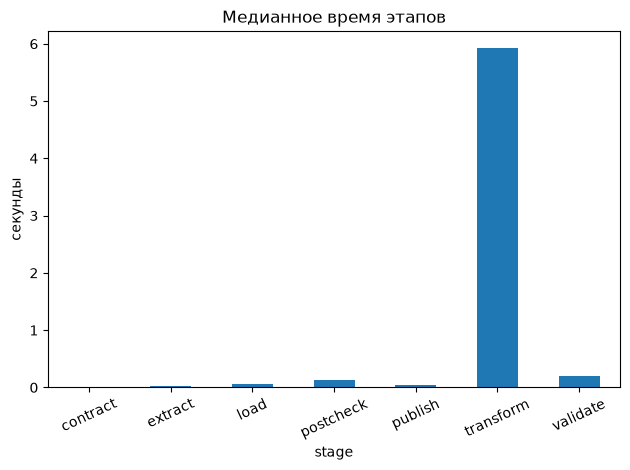

,message,created_at
0,"SLA: превышен бюджет обработки, предыдущая вит...",2026-11-12 20:41:33.719784+07:00
1,DLQ: отклонено 1 записей,2026-11-12 20:41:07.004317+07:00
2,Schema drift: дополнительные поля сохранены в ...,2026-11-12 20:39:59.546887+07:00
3,Schema drift: применён совместимый алиас kille...,2026-11-12 20:39:59.521127+07:00
4,DLQ: отклонено 3 записей,2026-11-12 20:39:51.824168+07:00
5,DLQ: отклонено 3 записей,2026-11-12 20:39:42.473251+07:00


In [10]:
schedule = CronSchedule(cron='0 5 * * *', timezone='Europe/Moscow')
print(schedule.model_dump(mode='json'))
healthy = run(batch)
assert healthy['ok'], healthy['error']
print('Prefect flow run:', healthy['result']['run_id'])
if os.environ.get('PREFECT_API_URL'):
    ui = os.environ['PREFECT_API_URL'].removesuffix('/api')
    display(HTML(f"<a href='{ui}/runs/flow-run/{healthy['result']['run_id']}'>Открыть запуск в Prefect UI</a>"))
show_monitoring()

## Часть 5. Great Expectations

Покажу проваленные проверки на плохих данных и результат после очистки. HTML-отчёты лежат в рабочей папке.

In [11]:
bad_report = quality(mixed, 'bad_demo')
good_report = quality(batch, 'good_demo')
assert not bad_report['успех'].all() and good_report['успех'].all()
display(HTML(bad_report.to_html(index=False)))
display(HTML(good_report.to_html(index=False)))

20:41:41.842 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp2flah_l9' for ephemeral docs site

20:41:41.940 | INFO    | great_expectations.data_context.types.base - Created temporary directory 'C:\Users\Anton\AppData\Local\Temp\tmp62p3net2' for ephemeral docs site

проверка,поле,успех,нарушений
expect_column_values_to_not_be_null,accident_id,True,0
expect_column_values_to_be_unique,accident_id,True,0
expect_column_values_to_not_be_null,reg_code,True,0
expect_column_values_to_be_in_set,reg_code,False,1
expect_column_values_to_not_be_null,dt,False,1
expect_column_values_to_not_be_null,dead_n,True,0
expect_column_values_to_be_between,dead_n,False,1
expect_column_values_to_not_be_null,injured_n,True,0
expect_column_values_to_be_between,injured_n,True,0
expect_column_values_to_not_be_null,vehicles_n,True,0


проверка,поле,успех,нарушений
expect_column_values_to_not_be_null,accident_id,True,0
expect_column_values_to_be_unique,accident_id,True,0
expect_column_values_to_not_be_null,reg_code,True,0
expect_column_values_to_be_in_set,reg_code,True,0
expect_column_values_to_not_be_null,dt,True,0
expect_column_values_to_not_be_null,dead_n,True,0
expect_column_values_to_be_between,dead_n,True,0
expect_column_values_to_not_be_null,injured_n,True,0
expect_column_values_to_be_between,injured_n,True,0
expect_column_values_to_not_be_null,vehicles_n,True,0


Проверки ловят пропуски, отрицательные счётчики и неизвестный регион. После загрузки связи и итоговые суммы дополнительно проверяет dbt.

## Часть 6. dbt

`stg_accidents` приводит дату, `dim_regions` хранит справочник, `fact_daily` собирает сводку. Макрос считает пострадавших. Тесты проверяют ключи, связи и совпадение итогов с источником.

,узел,статус,секунды
0,seed.dtp_lab.dim_regions,success,0.124707
1,model.dtp_lab.stg_accidents,success,0.146791
2,test.dtp_lab.not_null_dim_regions_reg_code.41f...,pass,0.049291
3,test.dtp_lab.unique_dim_regions_reg_code.bd8d7...,pass,0.033787
4,test.dtp_lab.not_null_stg_accidents_accident_i...,pass,0.025240
5,test.dtp_lab.not_null_stg_accidents_reg_code.f...,pass,0.024721
6,test.dtp_lab.relationships_stg_accidents_reg_c...,pass,0.033419
7,test.dtp_lab.unique_stg_accidents_accident_id....,pass,0.034140
8,model.dtp_lab.fact_daily,success,0.032257
9,test.dtp_lab.not_null_fact_daily_day.5d2293a056,pass,0.020012


,day,reg_code,reg_name,accidents,dead,injured,victims
0,2025-01-01,1132,Кемеровская область - Кузбасс,5,0.0,6.0,6.0
1,2025-01-01,1140,гор. Санкт-Петербург,5,1.0,5.0,6.0
2,2025-01-01,1145,гор. Москва,14,0.0,15.0,15.0
3,2025-01-02,1132,Кемеровская область - Кузбасс,6,5.0,13.0,18.0
4,2025-01-02,1140,гор. Санкт-Петербург,6,0.0,6.0,6.0
5,2025-01-02,1145,гор. Москва,11,1.0,15.0,16.0
6,2025-01-03,1132,Кемеровская область - Кузбасс,2,0.0,5.0,5.0
7,2025-01-03,1140,гор. Санкт-Петербург,5,0.0,7.0,7.0


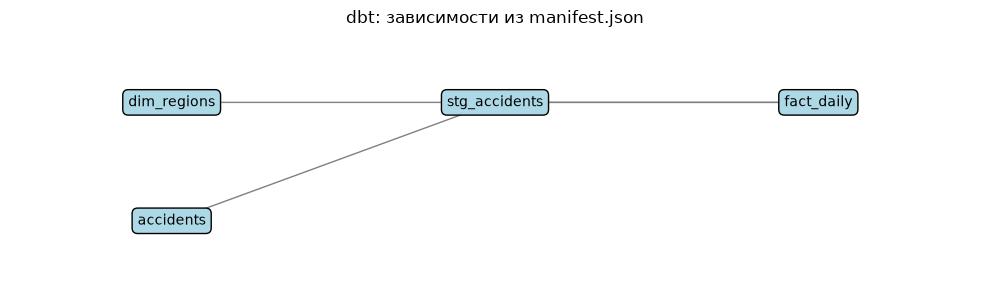

In [12]:
schema = healthy['result']['version']
results = json.loads((PROJECT / 'target/run_results.json').read_text(encoding='utf-8'))
dbt(['docs', 'generate'], schema)
display(pd.DataFrame([{'узел': r['unique_id'], 'статус': r['status'], 'секунды': r['execution_time']}
                      for r in results['results']]))
display(sql('SELECT * FROM analytics.daily ORDER BY day, reg_code LIMIT 8'))
show_lineage()

## Часть 7. CI/CD

[Конфиг CI](../.github/workflows/lab03.yml) запускает тесты на маленьком наборе и передаёт проверенный артефакт через staging в production. Workflow тестирует ноутбук и HTTP-деплой на временном стенде. Production job требует environment `production` с обязательным reviewer. Долгоживущий внешний сервер в этой работе не используется.

### Проверка публикации через HTTP

Стенд использует те же Parquet-релизы, что CI. Проверяю публикацию, canary 10%, откат при ошибке smoke test и сравнение бизнес-метрик. Изменение распределения по регионам оцениваю total variation distance (0 — совпадение, 1 — полное различие). Это индикатор изменения входных данных, а не оценка качества модели.


In [13]:
from lab_03.runtime import export_release
from lab_03.verify import deployment_demo

candidate = export_release(globals(), healthy['result'])
deployment_results = deployment_demo(candidate, WORK / 'deployment-demo')
display(pd.DataFrame(deployment_results['checks']))
display(pd.DataFrame(deployment_results['events']))
print('Отчёт:', WORK / 'deployment-demo' / 'verification.json')


,check,passed
0,staging + production HTTP smoke,True
1,10% canary + failed smoke + HTTP rollback,True
2,successful promotion after rollback,True
3,corrupted artifact rejected before publication,True
4,business metrics + regional distribution drift,True
5,injected regional drift triggers alert in staging,True


,at,channel,status,before,after,rows,accidents,victims,business_delta,region_distribution_tvd,drift_alert,error
0,2026-11-12T13:41:47.892425+00:00,staging,promoted,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,1093.0,14262.0,16733.0,"{'rows': 0, 'accidents': 0, 'victims': 0}",NaN,False,NaN
1,2026-11-12T13:41:47.916923+00:00,production,promoted,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,1093.0,14262.0,16733.0,"{'rows': 0, 'accidents': 0, 'victims': 0}",NaN,False,NaN
2,2026-11-12T13:41:47.958250+00:00,production,rolled_back,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,3f3690509f9e14c2786085b7fa851df7a1362be68adca6...,NaN,NaN,NaN,NaN,NaN,NaN,Injected HTTP smoke failure
3,2026-11-12T13:41:47.986065+00:00,production,promoted,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,3f3690509f9e14c2786085b7fa851df7a1362be68adca6...,1093.0,14262.0,16734.0,"{'rows': 0, 'accidents': 0, 'victims': 1}",0.000000,False,NaN
4,2026-11-12T13:41:48.040229+00:00,staging,promoted,4ecc1a978e81214c1ae6eb342f93ff5377310f31886b9c...,e9052174e3eea134bce21748e2ab1e0d93120e83d5e858...,1093.0,1014262.0,16734.0,"{'rows': 0, 'accidents': 1000000, 'victims': 1}",0.829635,True,NaN


Отчёт: C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab_03\sessions\3abf88c0bf\deployment-demo\verification.json


### Скриншоты

Запустил пайплайн через worker и проверил задачи в Prefect. Ниже скриншоты запуска и графа dbt Docs.

![Prefect: задачи ELT](evidence/prefect-tasks.jpg)

![Prefect: deployment](evidence/prefect-worker.jpg)

![dbt Docs: lineage](evidence/dbt-lineage.jpg)

В Prefect видно, на каком этапе выполняется пайплайн и сколько занимает каждая задача. Запуск по расписанию работает отдельно от опытов в ноутбуке.

Для отката сохраняю версии витрины в Parquet: в DuckDB нет встроенного Time Travel. Стабильный ключ и ревизии позволяют повторять загрузку без дубликатов и потери исправлений.


## Итоги

Получился локальный ELT с повторами, UPSERT, DLQ, проверками и версиями витрины. Битые данные не попадают в отчёт, а неудачная публикация оставляет предыдущую версию. Проверил публикацию по HTTP и автоматический откат. Ноутбук и staging также прошли [в GitHub Actions](https://github.com/restupkolpp-source/big_data/actions/runs/43230793996). Production запускается после merge и ручного подтверждения.

In [14]:
dlq_error_count = len(sql('SELECT * FROM dlq'))
data_quality_score = healthy['result']['quality_score']
pipeline_duration = healthy['result']['seconds']
assert idempotency_passed and dlq_error_count > 0 and data_quality_score == 1
snapshot = Path(sql('SELECT snapshot FROM versions WHERE version=?', [healthy['result']['version']]).iloc[0, 0])
release = {'snapshot': snapshot.name, 'sha256': hashlib.sha256(snapshot.read_bytes()).hexdigest(),
           'rows': signature()['rows'], 'accidents': signature()['accidents']}
(WORK / 'release.json').write_text(json.dumps(release, ensure_ascii=False, indent=2), encoding='utf-8')
print('## METRICS ##')
print(f'IDEMPOTENCY_TEST_PASSED={idempotency_passed}')
print(f'DLQ_ERROR_COUNT={dlq_error_count}')
print(f'DATA_QUALITY_SCORE={data_quality_score:.2f}')
print(f'PIPELINE_DURATION_SEC={pipeline_duration:.2f}')

## METRICS ##
IDEMPOTENCY_TEST_PASSED=True
DLQ_ERROR_COUNT=4
DATA_QUALITY_SCORE=1.00
PIPELINE_DURATION_SEC=7.52
